# WEEK 5 – DATA AUDIT

## Aim

To perform a data quality audit on the cleaned job postings dataset by checking dataset structure, missing values, duplicate records, and data types.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
from google.colab import files

uploaded = files.upload()

Saving data_jobs_cleaned.csv to data_jobs_cleaned.csv


In [12]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (785640, 17)


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


## 1. Dataset Overview

In this step, we examine the basic structure of the cleaned job postings dataset, including the number of rows, columns, and sample records.


In [13]:
# Display number of rows and columns
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display first 5 records
print("\nFirst 5 Records:")
display(df.head())

Number of Rows: 785640
Number of Columns: 17

Column Names:
['job_title_short', 'job_title', 'job_location', 'job_via', 'job_schedule_type', 'job_work_from_home', 'search_location', 'job_posted_date', 'job_no_degree_mention', 'job_health_insurance', 'job_country', 'salary_rate', 'salary_year_avg', 'salary_hour_avg', 'company_name', 'job_skills', 'job_type_skills']

First 5 Records:


,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


## 2. Missing Values Analysis

In this step, we identify the number of missing values in each column of the cleaned job postings dataset. This helps us understand which columns contain incomplete information.


In [14]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
job_title_short               0
job_title                     0
job_location                  0
job_via                       0
job_schedule_type             0
job_work_from_home            0
search_location               0
job_posted_date               0
job_no_degree_mention         0
job_health_insurance          0
job_country                   0
salary_rate              752574
salary_year_avg          763638
salary_hour_avg          774978
company_name                  0
job_skills               116986
job_type_skills          116986
dtype: int64


In [15]:
# Calculate missing value percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Values Percentage:")
print(missing_percentage.round(2))

Missing Values Percentage:
job_title_short           0.00
job_title                 0.00
job_location              0.00
job_via                   0.00
job_schedule_type         0.00
job_work_from_home        0.00
search_location           0.00
job_posted_date           0.00
job_no_degree_mention     0.00
job_health_insurance      0.00
job_country               0.00
salary_rate              95.79
salary_year_avg          97.20
salary_hour_avg          98.64
company_name              0.00
job_skills               14.89
job_type_skills          14.89
dtype: float64


### Observation

1. Most columns have no missing values.
2. Salary-related columns contain a high percentage of missing values.
3. The `salary_hour_avg` column has the highest missing percentage (98.64%).
4. The `job_skills` and `job_type_skills` columns have 14.89% missing values.
5. Missing salary information may indicate that employers did not provide salary details in their job postings.

### Conclusion

The dataset contains incomplete information mainly in salary-related columns. These missing values should be handled carefully before performing salary-based analysis.


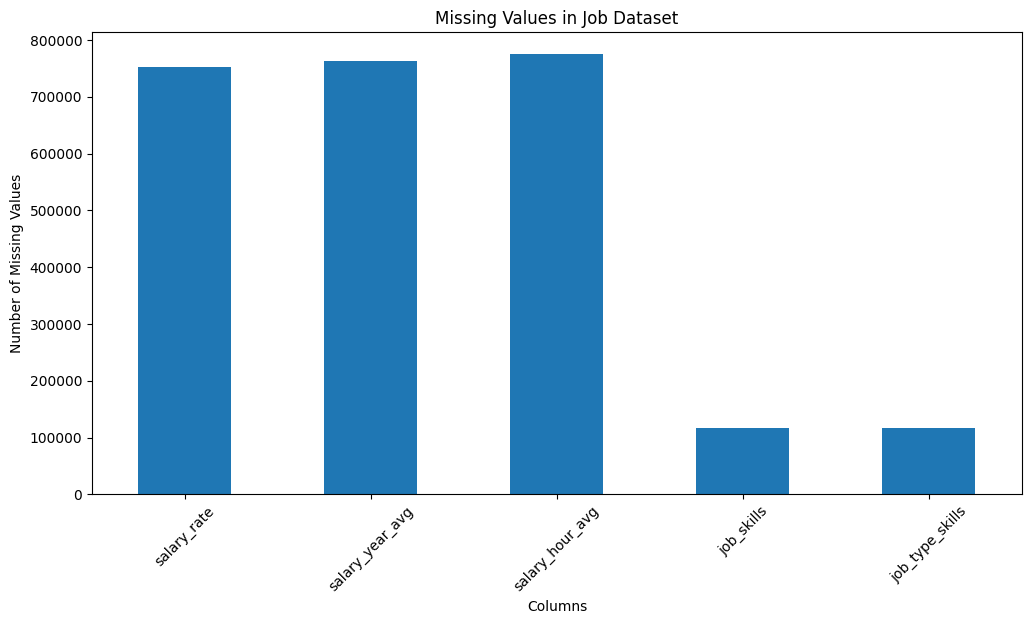

In [16]:
# Visualize missing values
plt.figure(figsize=(12, 6))

missing_values[missing_values > 0].plot(kind='bar')

plt.title("Missing Values in Job Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)

plt.show()

### Graph Observation

1. The graph shows missing values in five columns.
2. Salary-related columns have the highest missing values.
3. `salary_hour_avg` has the highest missing count.
4. `job_skills` and `job_type_skills` have comparatively fewer missing values.
5. The graph helps identify columns that need attention during data analysis.


## 3. Duplicate Records Analysis

In this step, we check whether the dataset contains duplicate records. Duplicate records may affect the accuracy of data analysis.


In [17]:
# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Records:", duplicate_count)

Number of Duplicate Records: 0


## 4. Data Types Analysis

In this step, we examine the data types of all columns in the dataset. This helps us understand the type of information stored in each column and identify columns that may require conversion.


In [18]:
# Display data types of all columns
print("Data Types of Each Column:")
print(df.dtypes)

Data Types of Each Column:
job_title_short           object
job_title                 object
job_location              object
job_via                   object
job_schedule_type         object
job_work_from_home          bool
search_location           object
job_posted_date           object
job_no_degree_mention       bool
job_health_insurance        bool
job_country               object
salary_rate               object
salary_year_avg          float64
salary_hour_avg          float64
company_name              object
job_skills                object
job_type_skills           object
dtype: object


The dataset contains different data types, including object, boolean, and numerical columns. The date column was converted into datetime format to support time-based analysis.


In [20]:
# Convert job_posted_date into datetime format
df['job_posted_date'] = pd.to_datetime(
    df['job_posted_date'],
        errors='coerce'
        )

        # Check the data type
print(df['job_posted_date'].dtype)

datetime64[ns]


In [21]:
print(df.dtypes)

job_title_short                  object
job_title                        object
job_location                     object
job_via                          object
job_schedule_type                object
job_work_from_home                 bool
search_location                  object
job_posted_date          datetime64[ns]
job_no_degree_mention              bool
job_health_insurance               bool
job_country                      object
salary_rate                      object
salary_year_avg                 float64
salary_hour_avg                 float64
company_name                     object
job_skills                       object
job_type_skills                  object
dtype: object


### Observation

1. The dataset contains object, boolean, and float data types.
2. Three columns contain boolean values.
3. Two columns contain numerical float values.
4. The `job_posted_date` column was converted from object to datetime format.

### Conclusion

The data types were examined, and the date column was converted into datetime format for future time-based analysis.


## 5. Date Analysis

In this step, we analyze the job posting dates by extracting the year and month from the `job_posted_date` column. This helps us understand the time-based distribution of job postings.


In [22]:
# Extract year
df['posted_year'] = df['job_posted_date'].dt.year

# Extract month
df['posted_month'] = df['job_posted_date'].dt.month

# Display the result
print(df[['job_posted_date', 'posted_year', 'posted_month']].head())

      job_posted_date  posted_year  posted_month
0 2023-06-16 13:44:15         2023             6
1 2023-01-14 13:18:07         2023             1
2 2023-10-10 13:14:55         2023            10
3 2023-07-04 13:01:41         2023             7
4 2023-08-07 14:29:36         2023             8


### Observation

1. The `job_posted_date` column was successfully converted into datetime format.
2. The year was extracted into a new column called `posted_year`.
3. The month was extracted into a new column called `posted_month`.
4. The sample records show that job postings belong to the year 2023, with different posting months.

### Conclusion

Date extraction helps us perform time-based analysis and understand job posting trends across different months and years.


## 6. Final Data Audit Summary

The cleaned job postings dataset contains 785,640 rows and 17 original columns.

* Duplicate records: 0
* Salary-related columns contain a high percentage of missing values.
* Job skills columns contain 14.89% missing values.
* Most columns have valid data types.
* The `job_posted_date` column was converted into datetime format.
* Year and month features were extracted for future analysis.

### Conclusion

The data audit helped identify missing values, examine data types, check duplicate records, and prepare date features. The dataset is ready for further analysis, with appropriate handling of missing values in future steps.


## 7. Final Conclusion

The data audit was performed on the cleaned job postings dataset containing 785,640 records and 17 original columns.

The analysis identified missing values, checked duplicate records, examined data types, and converted the job posting date into datetime format. Year and month features were also extracted.

The dataset is suitable for further data analysis, provided that missing values are handled appropriately during the upcoming stages.


In [23]:
print("Final Dataset Shape:", df.shape)
print("Duplicate Records:", df.duplicated().sum())
print("Date Data Type:", df['job_posted_date'].dtype)

Final Dataset Shape: (785640, 19)
Duplicate Records: 0
Date Data Type: datetime64[ns]
